# 01. Phân tích và làm sạch nhãn VNLP

Notebook này:
1. Đọc nhãn VNLP từ tên tệp (37.297 ảnh)
2. Kiểm tra định dạng tọa độ và định dạng biển số Việt Nam
3. Áp dụng các nhãn đã sửa bằng mắt (`data/labels/label_fixes.csv`)
4. Thống kê phân bố, phát hiện **trùng biển số giữa các ảnh** (nguồn gây rò rỉ dữ liệu)
5. Chia train/val/test **theo chuỗi biển** và lưu `data/labels/vnlp_manifest.csv`

Chỉ cần tên tệp nên chạy rất nhanh. Một số ô vẽ ảnh minh họa cần thư mục ảnh gốc `VNLP/detection/...`.
Đường dẫn tới dữ liệu khai báo trong `config.json` ở thư mục gốc project (xem `config.example.json`).

In [ ]:
import sys, csv, json, random, collections
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Thư mục project = thư mục cha của notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from alpr.plate_format import normalize, plate_format_for, province, display
from alpr.paths import load_paths

PATHS = load_paths()            # đường dẫn dữ liệu đọc từ config.json / config.example.json
VNLP = PATHS["vnlp_root"]       # dữ liệu gốc ở ổ E:, project ở ổ D:

SEED = 42
SPLIT_RATIO = {"train": 0.8, "val": 0.1, "test": 0.1}
pd.set_option("display.max_rows", 80)

## 1. Đọc nhãn từ tên tệp

Tên tệp có dạng `1_1463_1_36C09130_116_312_208_368.jpg`:
3 trường đầu là mã nội bộ, trường thứ tư là chuỗi biển, 4 số cuối là tọa độ hộp biển số.

In [2]:
SUBSETS = [  # (tệp danh sách, thư mục, loại biển, phương tiện)
    ("list_one_row.txt", "one_row", "1row", "car"),
    ("list_two_row.txt", "two_rows", "2row", "car"),
    ("list_two_rows_label_xe_may.txt", "two_rows_label_xe_may", "2row", "moto"),
]

records = []
for list_name, folder, ptype, vehicle in SUBSETS:
    lst = VNLP / "detection" / list_name
    if lst.exists():
        paths = [l.strip() for l in lst.read_text(encoding="utf-8").splitlines() if l.strip()]
    else:  # không có tệp danh sách thì quét thư mục
        paths = [f"/detection/{folder}/{p.name}" for p in sorted((VNLP / "detection" / folder).glob("*.jpg"))]
    for rel in paths:
        parts = Path(rel).stem.split("_")
        assert len(parts) == 8, rel
        x1, y1, x2, y2 = map(int, parts[4:])
        records.append(dict(rel_path=rel, subset=folder, plate_type=ptype, vehicle=vehicle,
                            raw_label=parts[3], x1=x1, y1=y1, x2=x2, y2=y2))

df = pd.DataFrame(records)
print(len(df), "ảnh")
df.groupby("subset").agg(so_anh=("rel_path", "size"),
                         so_bien_khac_nhau=("raw_label", lambda s: s.str.upper().nunique()))

37297 ảnh


,so_anh,so_bien_khac_nhau
subset,,
one_row,19086,16521
two_rows,12618,11648
two_rows_label_xe_may,5593,3227


## 2. Định dạng tọa độ: (x1, y1, x2, y2) hay (x, y, w, h)?

Readme gốc ghi 4 số cuối là "góc trên trái + rộng, cao". Kiểm tra:
- nếu là (x, y, w, h) thì `x + w` phải nhỏ hơn hoặc bằng 640 (chiều rộng ảnh);
- nếu là (x1, y1, x2, y2) thì luôn có `x2 > x1`.

In [3]:
as_xywh_out = ((df.x1 + df.x2) > 640).mean()
as_xyxy_ok = ((df.x2 > df.x1) & (df.y2 > df.y1)).mean()
print(f"Hiểu là (x,y,w,h): {as_xywh_out:.1%} hộp vượt ra ngoài ảnh rộng 640")
print(f"Hiểu là (x1,y1,x2,y2): {as_xyxy_ok:.1%} hộp hợp lệ")

# Vẽ thử một ảnh với cả hai cách hiểu
r = df.iloc[0]
p = VNLP / r.rel_path.lstrip("/")
if p.exists():
    im = Image.open(p)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for a, (title, box) in zip(ax, [("(x1,y1,x2,y2) - ĐÚNG", (r.x1, r.y1, r.x2 - r.x1, r.y2 - r.y1)),
                                    ("(x,y,w,h) - SAI", (r.x1, r.y1, r.x2, r.y2))]):
        a.imshow(im); a.add_patch(plt.Rectangle(box[:2], box[2], box[3], fill=False, ec="red", lw=2))
        a.set_title(title); a.axis("off")
    plt.show()
else:
    print("(Không tìm thấy ảnh gốc để vẽ minh họa)")

## 3. Chuẩn hóa và kiểm tra định dạng biển số

- Chuẩn hóa: chữ in hoa, bỏ dấu gạch và dấu chấm.
- Kiểm tra bằng biểu thức chính quy theo loại phương tiện (`src/alpr/plate_format.py`):
  ô tô `30A12345`; xe máy `29G141081`; xe máy điện `29MD...`; xe máy kiểu cũ `31960H4`; biển nước ngoài `29636NN479`.

In [4]:
df["label"] = df.raw_label.map(normalize)
print("Nhãn viết thường:", (df.raw_label != df.raw_label.str.upper()).sum())
df["plate_format"] = [plate_format_for(s, v) for s, v in zip(df.label, df.vehicle)]
suspicious = df[df.plate_format.isna()]
print("Nhãn không khớp định dạng:", len(suspicious))
suspicious.groupby("subset").size()

Nhãn viết thường: 3715


Nhãn không khớp định dạng: 37


subset
one_row                  17
two_rows                 17
two_rows_label_xe_may     3
dtype: int64

### 3.1 Áp dụng các nhãn đã xem lại bằng mắt

Từng nhãn đáng ngờ đã được đối chiếu với ảnh và ghi vào `data/labels/label_fixes.csv`:
- `fixed`: nhãn sai, đã sửa theo ảnh
- `valid_special`: nhãn đúng nhưng là định dạng đặc biệt
- `unreadable`: không đọc được (giữ cho detection, bỏ khỏi OCR)

Nếu phát hiện thêm nhãn sai, chỉ cần thêm dòng vào tệp này và chạy lại notebook.

In [5]:
fixes = pd.read_csv(ROOT / "data/labels/label_fixes.csv", dtype=str).fillna("")
print(fixes.status.value_counts().to_string())
fixes.head(12)

status
fixed            37
valid_special    21
unreadable        1


,rel_path,raw_label,fixed_label,status,note
0,/detection/one_row/2_1068_1_36A041270_56_209_6...,36A041270,36A04270,fixed,Sửa theo ảnh
1,/detection/one_row/1_1957_1_B36M2390_117_269_5...,B36M2390,36M2390,fixed,Sửa theo ảnh
2,/detection/one_row/2_1070_1_36A392693_90_217_5...,36A392693,36A39263,fixed,Sửa theo ảnh
3,/detection/one_row/1_1955_1_B14A14304_23_207_5...,B14A14304,14A14304,fixed,Sửa theo ảnh
4,/detection/one_row/1_2195_1_30E337533_145_217_...,30E337533,30E35733,fixed,Sửa theo ảnh
5,/detection/one_row/1_1959_1_BC36C26957_61_230_...,BC36C26957,36C26957,fixed,Sửa theo ảnh
6,/detection/one_row/9_1780_1_36A439261_50_323_1...,36A439261,36A43926,fixed,Sửa theo ảnh
7,/detection/one_row/5_3937_1_36C231710_105_211_...,36C231710,36C23170,fixed,Sửa theo ảnh
8,/detection/one_row/1_1956_1_B36A38895_96_188_6...,B36A38895,36A38895,fixed,Sửa theo ảnh
9,/detection/one_row/1_1961_1_BD36N1662_148_208_...,BD36N1662,36N1662,fixed,Sửa theo ảnh


In [6]:
fx = fixes.set_index("rel_path")
df["label_status"] = "ok"
m_fixed = df.rel_path.isin(fx.index[fx.status == "fixed"])
df.loc[m_fixed, "label"] = df.loc[m_fixed, "rel_path"].map(fx.fixed_label)
df.loc[m_fixed, "label_status"] = "fixed"
m_unread = df.rel_path.isin(fx.index[fx.status == "unreadable"])
df.loc[m_unread, ["label", "label_status"]] = ["", "unreadable"]

df["plate_format"] = [plate_format_for(s, v) if s else None for s, v in zip(df.label, df.vehicle)]
still_bad = df[(df.label != "") & df.plate_format.isna()]
df.loc[still_bad.index, "label_status"] = "invalid"
print("Còn lại nhãn chưa hợp lệ:", len(still_bad))
df.label_status.value_counts()

Còn lại nhãn chưa hợp lệ: 0


label_status
ok            37259
fixed            37
unreadable        1
Name: count, dtype: int64

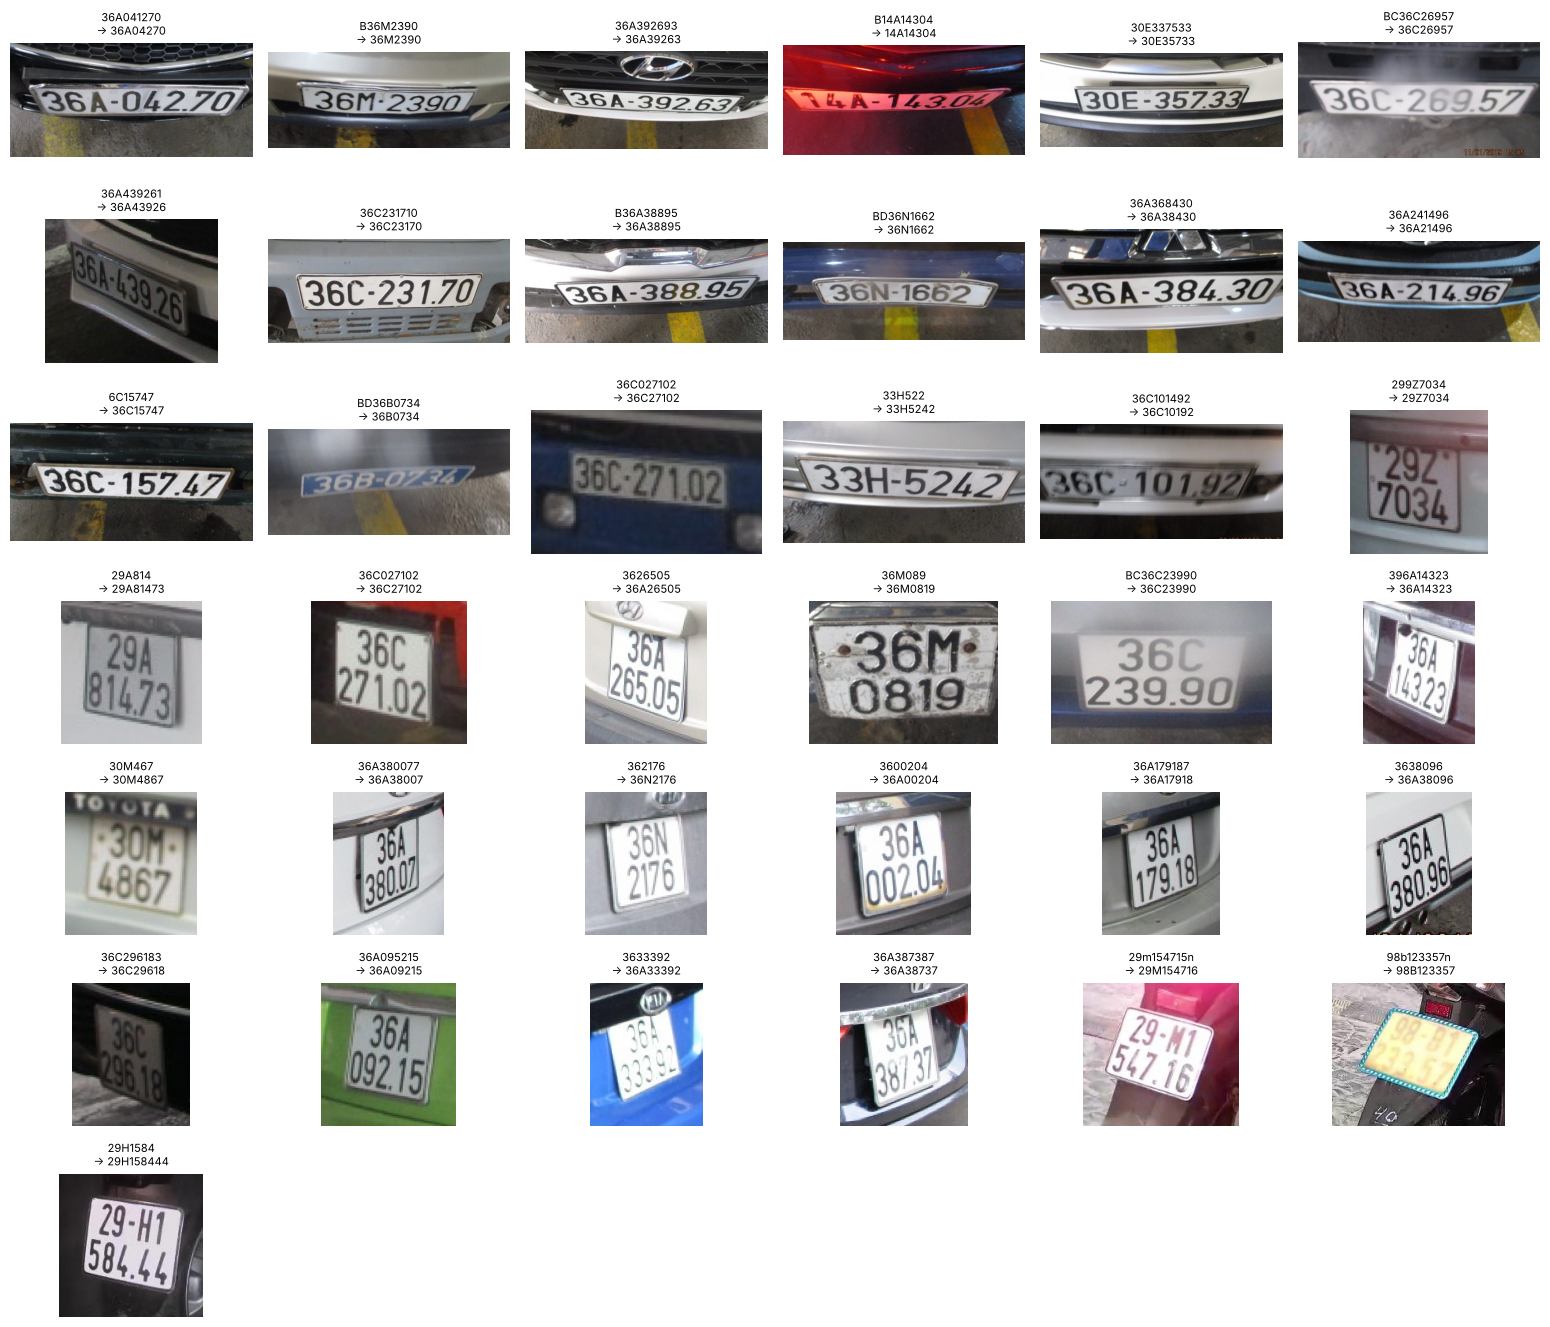

In [7]:
# Xem lại ảnh của các nhãn đã sửa (cần ảnh gốc)
def show_crops(rows, ncol=6, title_col="label"):
    rows = [r for _, r in rows.iterrows() if (VNLP / r.rel_path.lstrip("/")).exists()]
    if not rows:
        print("(Không tìm thấy ảnh gốc)"); return
    nrow = (len(rows) + ncol - 1) // ncol
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 2.6, nrow * 1.9))
    for ax in np.array(axes).ravel():
        ax.axis("off")
    for ax, r in zip(np.array(axes).ravel(), rows):
        im = Image.open(VNLP / r.rel_path.lstrip("/"))
        m = max(r.x2 - r.x1, r.y2 - r.y1) * 0.2
        ax.imshow(im.crop((max(0, r.x1 - m), max(0, r.y1 - m), min(im.width, r.x2 + m), min(im.height, r.y2 + m))))
        ax.set_title(f"{r.raw_label}\n→ {r[title_col]}", fontsize=8)
    plt.tight_layout(); plt.show()

show_crops(df[df.label_status == "fixed"])

## 4. Thống kê phân bố

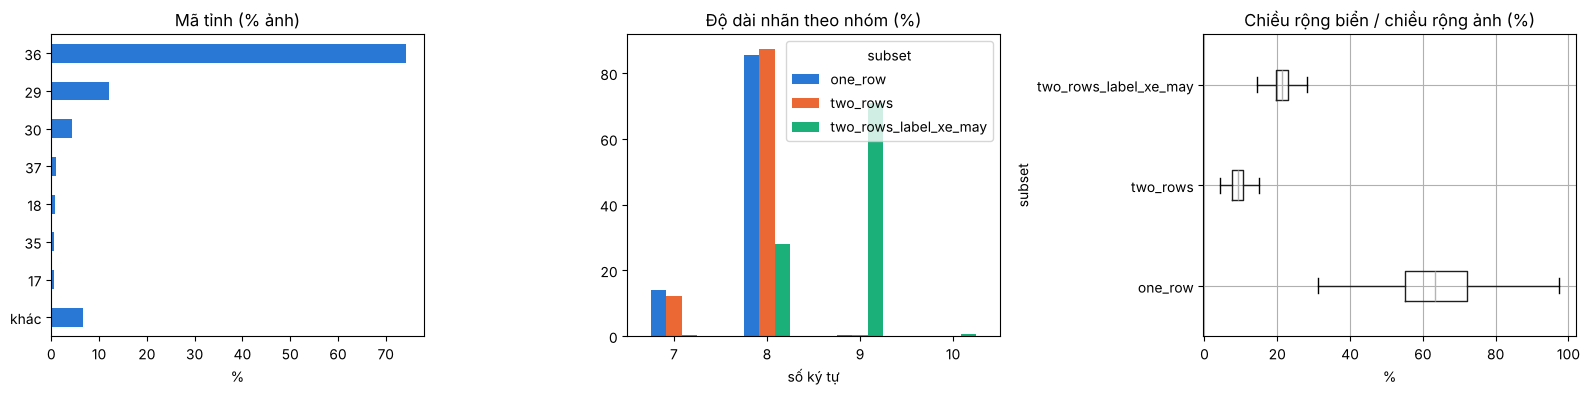

Mã 36 chiếm 74.2%; số mã tỉnh: 70; mã có < 20 ảnh: 32


In [8]:
ok = df[df.label != ""].copy()
ok["province"] = ok.label.map(province)
ok["len"] = ok.label.str.len()
ok["rel_w"] = (ok.x2 - ok.x1) / 640 * 100
colors = {"one_row": "#2a78d6", "two_rows": "#eb6834", "two_rows_label_xe_may": "#1baf7a"}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
top = ok.province.value_counts()
top = pd.concat([top.head(7), pd.Series({"khác": top.iloc[7:].sum()})])
(top / top.sum() * 100).plot.barh(ax=ax[0], color="#2a78d6"); ax[0].invert_yaxis()
ax[0].set_title("Mã tỉnh (% ảnh)"); ax[0].set_xlabel("%")
pd.crosstab(ok.len, ok.subset, normalize="columns").mul(100).plot.bar(
    ax=ax[1], color=[colors[c] for c in sorted(colors)], rot=0)
ax[1].set_title("Độ dài nhãn theo nhóm (%)"); ax[1].set_xlabel("số ký tự")
ok.boxplot(column="rel_w", by="subset", ax=ax[2], vert=False, showfliers=False)
ax[2].set_title("Chiều rộng biển / chiều rộng ảnh (%)"); ax[2].set_xlabel("%"); fig.suptitle("")
plt.tight_layout(); plt.show()

print(f"Mã 36 chiếm {(ok.province == '36').mean():.1%}; số mã tỉnh: {ok.province.nunique()}; "
      f"mã có < 20 ảnh: {(ok.province.value_counts() < 20).sum()}")

## 5. Trùng biển số giữa các ảnh: nguồn rò rỉ dữ liệu

Cùng một biển xuất hiện ở nhiều ảnh (khung hình liên tiếp của xe máy; ô tô chụp cả **đầu xe**
trong `one_row` lẫn **đuôi xe** trong `two_rows`). Nếu chia ngẫu nhiên, tập test sẽ chứa những biển
mô hình đã thấy khi huấn luyện.

In [9]:
cnt = ok.label.value_counts()
print(f"Biển khác nhau: {ok.label.nunique()} / {len(ok)} ảnh")
print(f"Ảnh có biển trùng với ảnh khác: {(ok.label.map(cnt) > 1).sum()} ({(ok.label.map(cnt) > 1).mean():.1%})")
subsets_of = ok.groupby("label").subset.agg(lambda s: tuple(sorted(set(s))))
print("\nBiển xuất hiện ở những thư mục nào:")
print(subsets_of.value_counts().to_string())

# Mô phỏng chia ngẫu nhiên từng ảnh
rng = np.random.default_rng(0)
u = rng.random(len(ok))
rand_split = np.where(u < 0.8, "train", np.where(u < 0.9, "val", "test"))
train_plates = set(ok.label[rand_split == "train"])
leak = ok.label[rand_split == "test"].isin(train_plates).mean()
print(f"\nNếu chia ngẫu nhiên: {leak:.1%} ảnh test có biển đã nằm trong train")

Biển khác nhau: 20911 / 37296 ảnh
Ảnh có biển trùng với ảnh khác: 29304 (78.6%)



Biển xuất hiện ở những thư mục nào:
subset
(one_row, two_rows)         10465
(one_row,)                   6046
(two_rows_label_xe_may,)     3224
(two_rows,)                  1176

Nếu chia ngẫu nhiên: 65.7% ảnh test có biển đã nằm trong train


## 6. Chia train/val/test theo chuỗi biển (group split)

Mỗi chuỗi biển là một nhóm; cả nhóm vào cùng một tập. Phân tầng theo thư mục để tỷ lệ 3 nhóm ảnh tương đương.

In [10]:
df["group"] = np.where(df.label != "", df.label, "_unreadable_" + df.rel_path)
first_subset = df.groupby("group", sort=False).subset.first()
sizes = df.groupby("group", sort=False).size()
rng = random.Random(SEED)
split_of = {}
for subset, groups in first_subset.groupby(first_subset):
    g = list(groups.index); rng.shuffle(g)
    total, acc = sizes[g].sum(), 0
    for name in g:
        f = acc / total
        split_of[name] = "train" if f < SPLIT_RATIO["train"] else (
            "val" if f < SPLIT_RATIO["train"] + SPLIT_RATIO["val"] else "test")
        acc += sizes[name]
df["split"] = df.group.map(split_of)
df["province"] = df.label.map(province)
df["use_for_ocr"] = df.label_status.isin(["ok", "fixed"]).astype(int)

leak_groups = df[df.label != ""].groupby("label").split.nunique().gt(1).sum()
print("Số biển nằm ở nhiều hơn một tập:", leak_groups)
tab = pd.crosstab(df.split, df.subset, margins=True)
tab["ty_le_ma_36"] = df.groupby("split").province.apply(lambda s: f"{(s == '36').mean():.1%}")
tab

Số biển nằm ở nhiều hơn một tập: 0


subset,one_row,two_rows,two_rows_label_xe_may,All,ty_le_ma_36
split,,,,,
test,1899,1269,559,3727,74.6%
train,15258,10108,4475,29841,74.1%
val,1929,1241,559,3729,74.3%
All,19086,12618,5593,37297,NaN


## 7. Lưu kết quả

In [11]:
cols = ["rel_path", "subset", "plate_type", "vehicle", "raw_label", "label", "label_status", "plate_format",
        "province", "x1", "y1", "x2", "y2", "group", "split", "use_for_ocr"]
out = ROOT / "data/labels/vnlp_manifest.csv"
df[cols].fillna("").to_csv(out, index=False, encoding="utf-8")

summary = {
    "total_images": len(df),
    "unique_plates": int(ok.label.nunique()),
    "label_status": df.label_status.value_counts().to_dict(),
    "split_images": df.split.value_counts().to_dict(),
    "random_split_test_leak": round(float(leak), 3),
    "plate_leak_between_splits": int(leak_groups),
}
(ROOT / "reports").mkdir(exist_ok=True)
(ROOT / "reports/label_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã lưu", out)
summary

Đã lưu data/labels/vnlp_manifest.csv


{'total_images': 37297,
 'unique_plates': 20911,
 'label_status': {'ok': 37259, 'fixed': 37, 'unreadable': 1},
 'split_images': {'train': 29841, 'val': 3729, 'test': 3727},
 'random_split_test_leak': 0.657,
 'plate_leak_between_splits': 0}

## Kết luận

- Tọa độ trong tên tệp là **(x1, y1, x2, y2)**.
- 59 nhãn đáng ngờ: 37 nhãn sai đã sửa, 21 nhãn đúng định dạng đặc biệt, 1 nhãn không đọc được.
- Mất cân bằng mạnh: mã 36 chiếm khoảng 74%.
- **Trùng biển rất nhiều**, kể cả giữa `one_row` và `two_rows` (cùng xe, đầu và đuôi). Bắt buộc chia theo biển.
- Bước tiếp theo: `02_kiem_tra_anh.ipynb` (ảnh hỏng, ảnh gần trùng) rồi `03_tao_dataset.ipynb`.